# Belguith Ahmed Rami — 22516111
# Benboubaker Majdi — 22517042

In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import requests
import zipfile
import io
import numpy as np


import tensorflow as tf
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
       
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import TextVectorization
from tensorflow.keras.utils import register_keras_serializable
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from keras.models import load_model
from tensorflow.keras.metrics import Mean
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.models import load_model

from UTILS import preview_images_from_dir
from UTILS import plot_training_curves
import warnings
warnings.filterwarnings(
    "ignore",
    category=FutureWarning,
    module="keras"
)

# Pour utiliser au mieux le GPU
AUTOTUNE = tf.data.AUTOTUNE

/home/rami/miniconda3/lib/python3.12/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


# Initialisation du dataset Flickr V2

In [3]:
@register_keras_serializable()
class L2Normalize(layers.Layer):
    def __init__(self, axis=-1, **kwargs):
        super().__init__(**kwargs)
        self.axis = axis

    def call(self, inputs):
        return tf.math.l2_normalize(inputs, axis=self.axis)

    def get_config(self):
        config = super().get_config()
        config.update({"axis": self.axis})
        return config

In [4]:
url = "https://www.lirmm.fr/~poncelet/Ressources/flickr_long_subset.zip"
target_dir = "flickr_subset2"

# Vérifie si le dossier existe déjà
if os.path.exists(target_dir) and os.path.isdir(target_dir):
    print("Données déjà disponibles dans :", target_dir)
else:
    print("Téléchargement de flickr_subset2.zip...")
    response = requests.get(url)
    if response.status_code == 200:
        print("Téléchargement réussi. Extraction...")
        with zipfile.ZipFile(io.BytesIO(response.content)) as zip_ref:
            # Extraire sans ajouter de sous-dossier supplémentaire
            for member in zip_ref.namelist():
                # Corrige les chemins pour ignorer un éventuel prefixe flickr_subset2/
                member_path = member
                if member.startswith("flickr_subset2/"):
                    member_path = member[len("flickr_subset2/"):]
                target_path = os.path.join(target_dir, member_path)

                # Si c'est un répertoire, on le crée
                if member.endswith("/"):
                    os.makedirs(target_path, exist_ok=True)
                else:
                    os.makedirs(os.path.dirname(target_path), exist_ok=True)
                    with zip_ref.open(member) as source, open(target_path, "wb") as target:
                        target.write(source.read())
        print(f"Données extraites dans : {target_dir}")
    else:
        print("Échec du téléchargement. Code HTTP :", response.status_code)


Données déjà disponibles dans : flickr_subset2


In [5]:
# Répertoire cible pour sauvegarder vos modèles
model_dir = "./models_forclip"
os.makedirs(model_dir, exist_ok=True)

# Répertoire des données
dataset_dir = "./flickr_subset2/flickr_long_subset"

# Répertoire des images
image_dir = os.path.join(dataset_dir, "images")
# Répertoire des captions
captions_dir = os.path.join(dataset_dir, "captions")

# Variables utiles
# Attention respecter bien l'ordre alphabétique des classes pour
# le générateur
class_names = ['ball', 'bike', 'dog', 'water']
# Pour les images
image_size=(224, 224)
image_shape = image_size + (3,)

# Pour les textes
sequence_length = 32
vocab_size = 10000
num_heads = 4
ff_dim = 256
num_layers = 2

# Pour les images et les textes dans le modèle CLIP
embed_dim = 128

Found 640 images belonging to 4 classes.


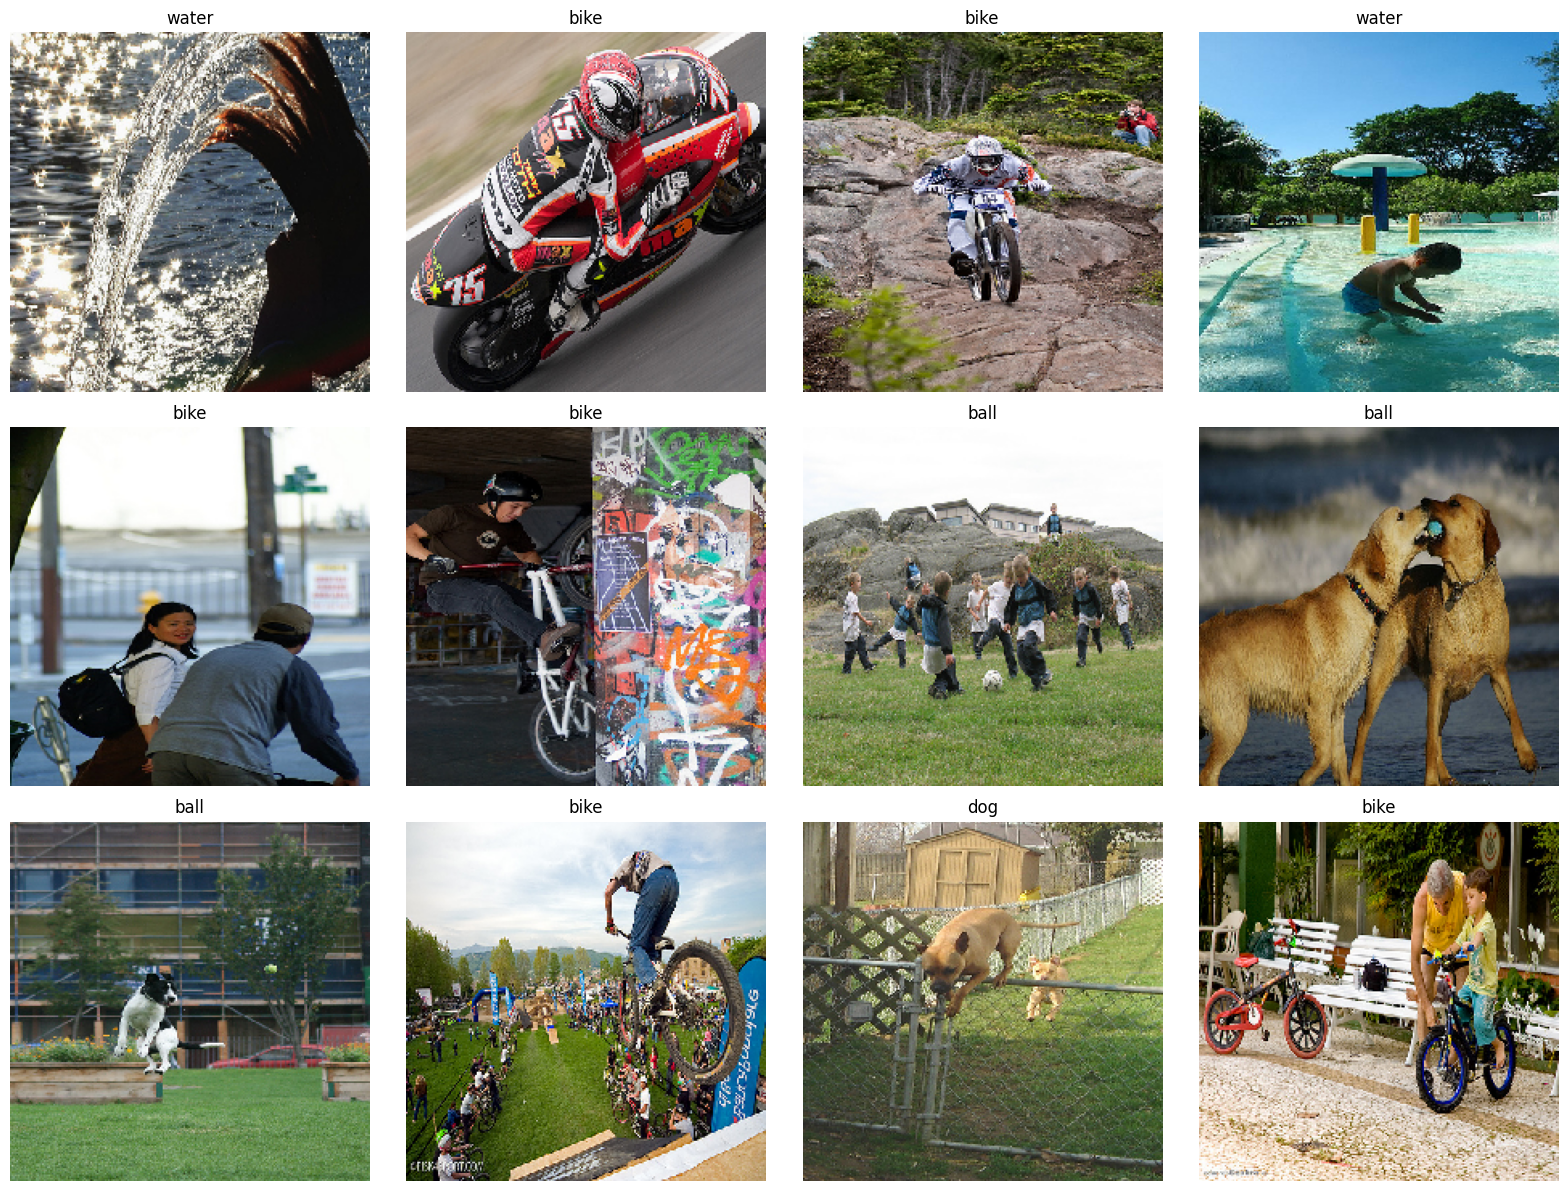

In [6]:
# Affichage des images
preview_images_from_dir(image_dir, image_size=image_size, n=12, subset="training", seed=42)

# ============================================================
# 1) DATA — Chargement image dataset 
# ============================================================

In [7]:
def make_image_generators(
    image_dir,
    image_size=(224, 224),
    batch_size=32,
    val_split=0.2,
    seed=123
):
    datagen = tf.keras.preprocessing.image.ImageDataGenerator(
        rescale=1./255,
        validation_split=val_split
    )

    train_gen = datagen.flow_from_directory(
        image_dir,
        target_size=image_size,
        batch_size=batch_size,
        class_mode="categorical",
        subset="training",
        shuffle=True,
        seed=seed
    )

    val_gen = datagen.flow_from_directory(
        image_dir,
        target_size=image_size,
        batch_size=batch_size,
        class_mode="categorical",
        subset="validation",
        shuffle=False,
        seed=seed
    )

    return train_gen, val_gen

# ============================================================
# 2) MODELE — CNN Classifieur (Dense(4)+softmax)
# ============================================================

In [8]:
def build_image_classifier(
    image_shape=(224, 224, 3),
    num_classes=4
):
    inp = layers.Input(shape=image_shape, name="img_input")

    x = layers.Conv2D(32, 3, padding="same", activation="relu")(inp)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Flatten(name="flatten")(x)

    # Petite couche dense
    x = layers.Dense(256, activation="relu", name="cls_dense")(x)
    x = layers.Dropout(0.2)(x)

    out = layers.Dense(num_classes, activation="softmax", name="cls_head")(x)

    model = Model(inp, out, name="image_classifier")
    return model

# ============================================================
# 3) TRAIN — Entraîner le classifieur
# + retourne history (loss/accuracy) pour reporting
# ============================================================

In [9]:
def train_image_classifier(
    image_dir,
    image_size=(224, 224),
    batch_size=32,
    epochs=8,
    val_split=0.2,
    seed=123,
    lr=1e-3
):
    image_shape = image_size + (3,)
    train_gen, val_gen = make_image_generators(
        image_dir=image_dir,
        image_size=image_size,
        batch_size=batch_size,
        val_split=val_split,
        seed=seed
    )

    num_classes = train_gen.num_classes
    class_names = list(train_gen.class_indices.keys())
    print("Classes (ordre):", class_names)

    model = build_image_classifier(image_shape=image_shape, num_classes=num_classes)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2, restore_best_weights=True
        )
    ]

    history = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=epochs,
        callbacks=callbacks
    )

    # Résultats minimaux (pour rapport)
    best_val_acc = float(np.max(history.history.get("val_accuracy", [np.nan])))
    best_val_loss = float(np.min(history.history.get("val_loss", [np.nan])))
    print(f"Best val_accuracy={best_val_acc:.4f} | Best val_loss={best_val_loss:.4f}")

    return model, history, class_names

# ============================================================
# 4) SAVE
# ============================================================

In [10]:
def save_image_classifier(model, save_path):
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    model.save(save_path)
    print("Classifieur image sauvegardé:", save_path)


# ============================================================
# 5) CONVERSION — Dériver l’encodeur image pour CLIP
# Conformité énoncé:
# - enlever couches de classification (jusqu’à flatten inclus)
# - sortie: Dense(embed_dim) sans activation
# - normaliser (L2) pour CLIP
# ============================================================

In [11]:
def build_image_encoder_from_classifier(
    image_classifier,
    embed_dim=128,
    cut_layer_name="flatten"
):
    """
    image_classifier: modèle Keras entraîné
    cut_layer_name  : on coupe au niveau de cette couche (incluse)
                      -> ici "flatten" (conforme à l’énoncé)
    """
    # 1) Récupérer la sortie de la couche "flatten"
    feat = image_classifier.get_layer(cut_layer_name).output

    # 2) Projeter en embeddings (sans activation)
    emb = layers.Dense(embed_dim, activation=None, name="img_embed")(feat)

    # 3) Normalisation L2 (souvent nécessaire en CLIP)
    emb = L2Normalize(name="img_l2norm")(emb)


    encoder = Model(
        inputs=image_classifier.input,
        outputs=emb,
        name="image_encoder"
    )
    return encoder

# ============================================================
# 6) EXEMPLE D’UTILISATION (à intégrer à ton notebook)
# ============================================================

Found 640 images belonging to 4 classes.
Found 160 images belonging to 4 classes.
Classes (ordre): ['ball', 'bike', 'dog', 'water']
Epoch 1/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 161ms/step - accuracy: 0.2781 - loss: 2.0794 - val_accuracy: 0.2500 - val_loss: 1.3982
Epoch 2/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - accuracy: 0.3328 - loss: 1.3413 - val_accuracy: 0.3125 - val_loss: 1.3861
Epoch 3/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 120ms/step - accuracy: 0.4641 - loss: 1.2271 - val_accuracy: 0.2625 - val_loss: 1.5328
Epoch 4/8
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 120ms/step - accuracy: 0.4812 - loss: 1.1308 - val_accuracy: 0.3063 - val_loss: 1.5262
Best val_accuracy=0.3125 | Best val_loss=1.3861
Classifieur image sauvegardé: ./models_forclip/image_classifier.keras


Model: "image_encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ img_input (InputLayer)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ img_embed (Dense)               │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ img_l2norm (L2Normalize)        │ (None, 128)            │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,938,432 (49.36 MB)

 Trainable params: 12,938,432 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

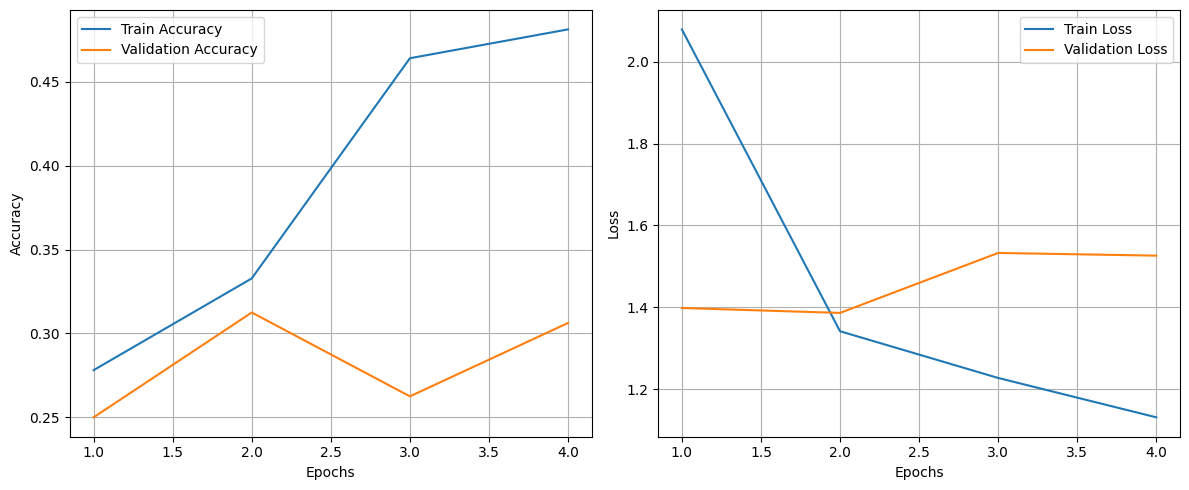

In [13]:

if __name__ == "__main__":
    # Exemple: adapte ces variables à ton notebook
    dataset_dir = "./flickr_subset2/flickr_long_subset"
    image_dir = os.path.join(dataset_dir, "images")
    model_dir = "./models_forclip"
    os.makedirs(model_dir, exist_ok=True)

    # 1) Entraîner le classifieur image
    clf, hist, class_names = train_image_classifier(
        image_dir=image_dir,
        image_size=(224, 224),
        batch_size=32,
        epochs=8,
        val_split=0.2
    )

    # 2) Sauvegarder (optionnel)
    clf_path = os.path.join(model_dir, "image_classifier.keras")
    save_image_classifier(clf, clf_path)

    # 3) Dériver l’encodeur image (CLIP)
    embed_dim = 128
    img_encoder = build_image_encoder_from_classifier(
        image_classifier=clf,
        embed_dim=embed_dim,
        cut_layer_name="flatten"
    )
    img_encoder.summary()

    # 4) Test rapide de shape
    dummy = tf.random.uniform((2, 224, 224, 3))
    out = img_encoder(dummy)

    
    plot_training_curves(
        hist,
        save_path="./results/training_curves.png"
    )